# 1. INSTALL DEPENDENCIES & CONFIGURE KAGGLE API

In [1]:
!pip install -q kaggle

import os
from google.colab import files

# Upload your kaggle.json API key file
print("Upload your kaggle.json file:")
uploaded = files.upload()

# Configure Kaggle credentials
os.makedirs('/root/.kaggle', exist_ok=True)
!mv kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API configured successfully.")

Upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Kaggle API configured successfully.


# 2. DOWNLOAD & EXTRACT THE CHEST X-RAY PNEUMONIA DATASET


In [2]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia --unzip -p /content/chest_xray_data

import os

BASE_DIR = '/content/chest_xray_data/chest_xray'
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VAL_DIR = os.path.join(BASE_DIR, 'val')
TEST_DIR = os.path.join(BASE_DIR, 'test')

# Print directory structure
for split in ['train', 'val', 'test']:
    path = os.path.join(BASE_DIR, split)
    for cls in os.listdir(path):
        cls_path = os.path.join(path, cls)
        if os.path.isdir(cls_path):
            print(f"{split}/{cls}: {len(os.listdir(cls_path))} images")

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:49<00:00, 22.5MB/s]

train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images


# 3. IMPORT ALL REQUIRED LIBRARIES


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import random

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (Dense, Dropout, Flatten, GlobalAveragePooling2D,
                                      BatchNormalization, Input)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_curve, auc, precision_recall_curve)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# Set seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 4. EXPLORATORY DATA ANALYSIS (EDA)


# 4.1 Class distribution across splits

In [4]:
splits = {'Train': TRAIN_DIR, 'Validation': VAL_DIR, 'Test': TEST_DIR}
distribution = {}

for split_name, split_path in splits.items():
    normal = len(os.listdir(os.path.join(split_path, 'NORMAL')))
    pneumonia = len(os.listdir(os.path.join(split_path, 'PNEUMONIA')))
    distribution[split_name] = {'NORMAL': normal, 'PNEUMONIA': pneumonia}

dist_df = pd.DataFrame(distribution).T
print("Class Distribution:\n")
print(dist_df)
print(f"\nTotal images: {dist_df.values.sum()}")

Class Distribution:

            NORMAL  PNEUMONIA
Train         1341       3875
Validation       8          8
Test           234        390

Total images: 5856


# 4.2 Bar chart of class distribution


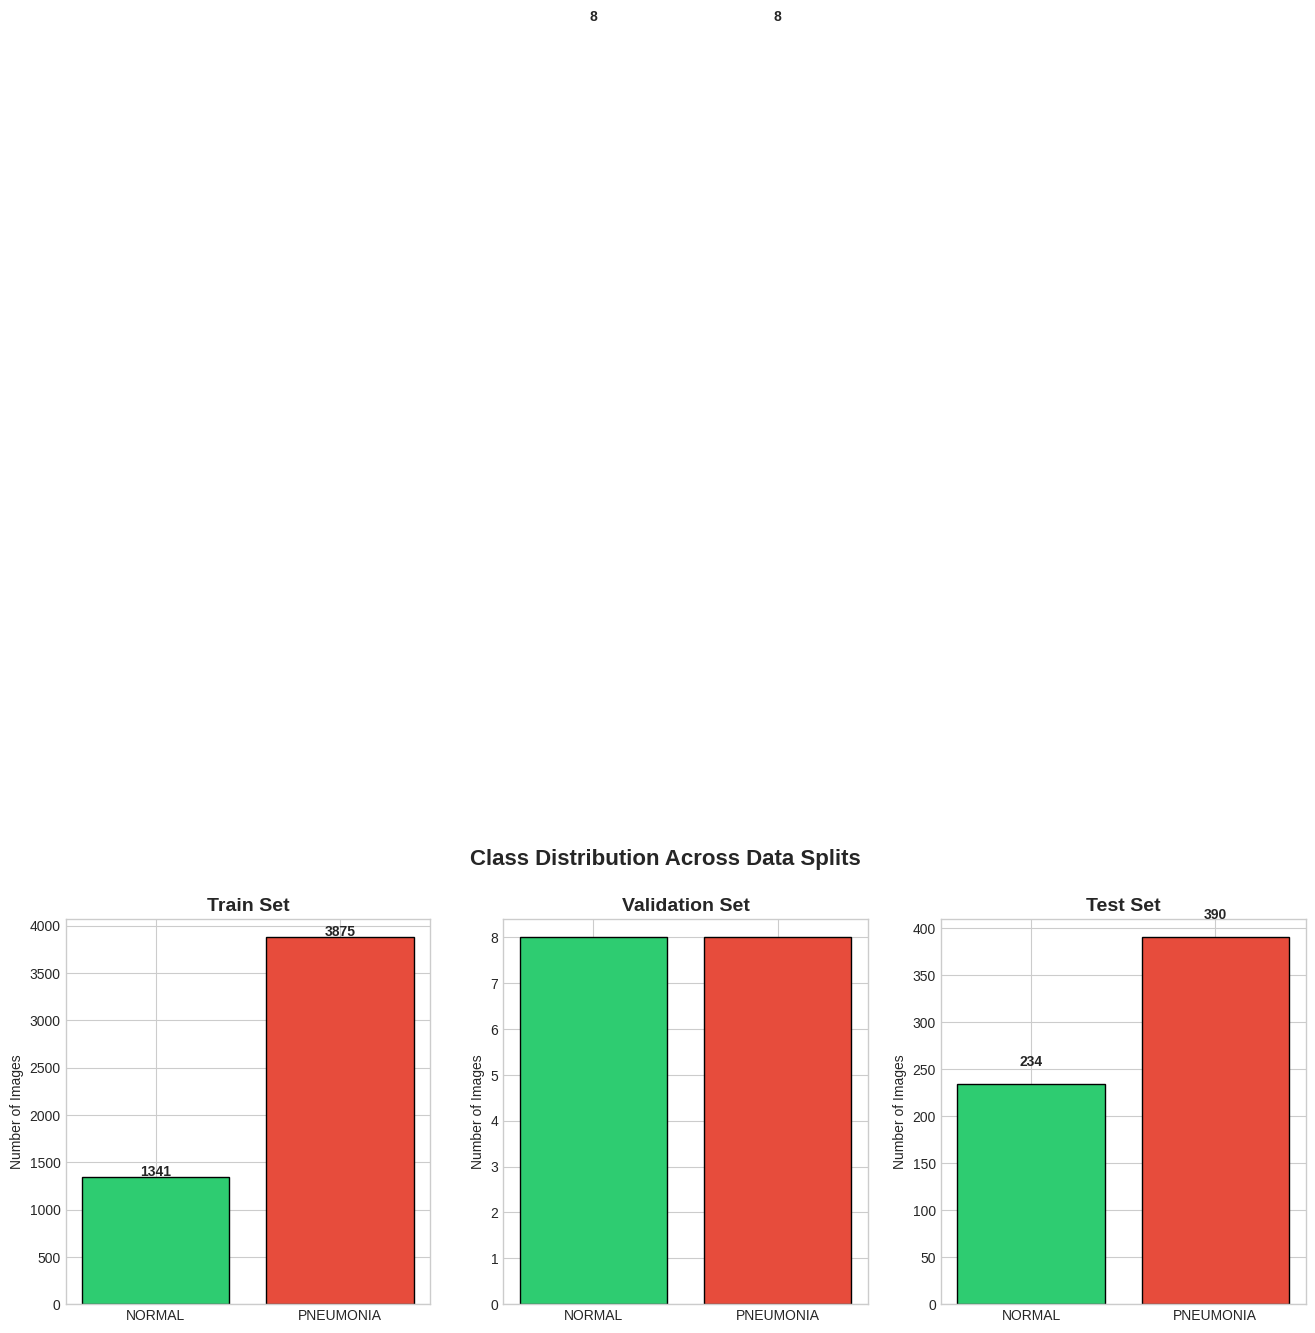

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#2ecc71', '#e74c3c']

for idx, (split_name, counts) in enumerate(distribution.items()):
    ax = axes[idx]
    bars = ax.bar(counts.keys(), counts.values(), color=colors, edgecolor='black')
    ax.set_title(f'{split_name} Set', fontsize=14, fontweight='bold')
    ax.set_ylabel('Number of Images')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 20,
                f'{int(bar.get_height())}', ha='center', fontweight='bold')

plt.suptitle('Class Distribution Across Data Splits', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# 5. SAMPLE CHEST X-RAY VISUALISATION


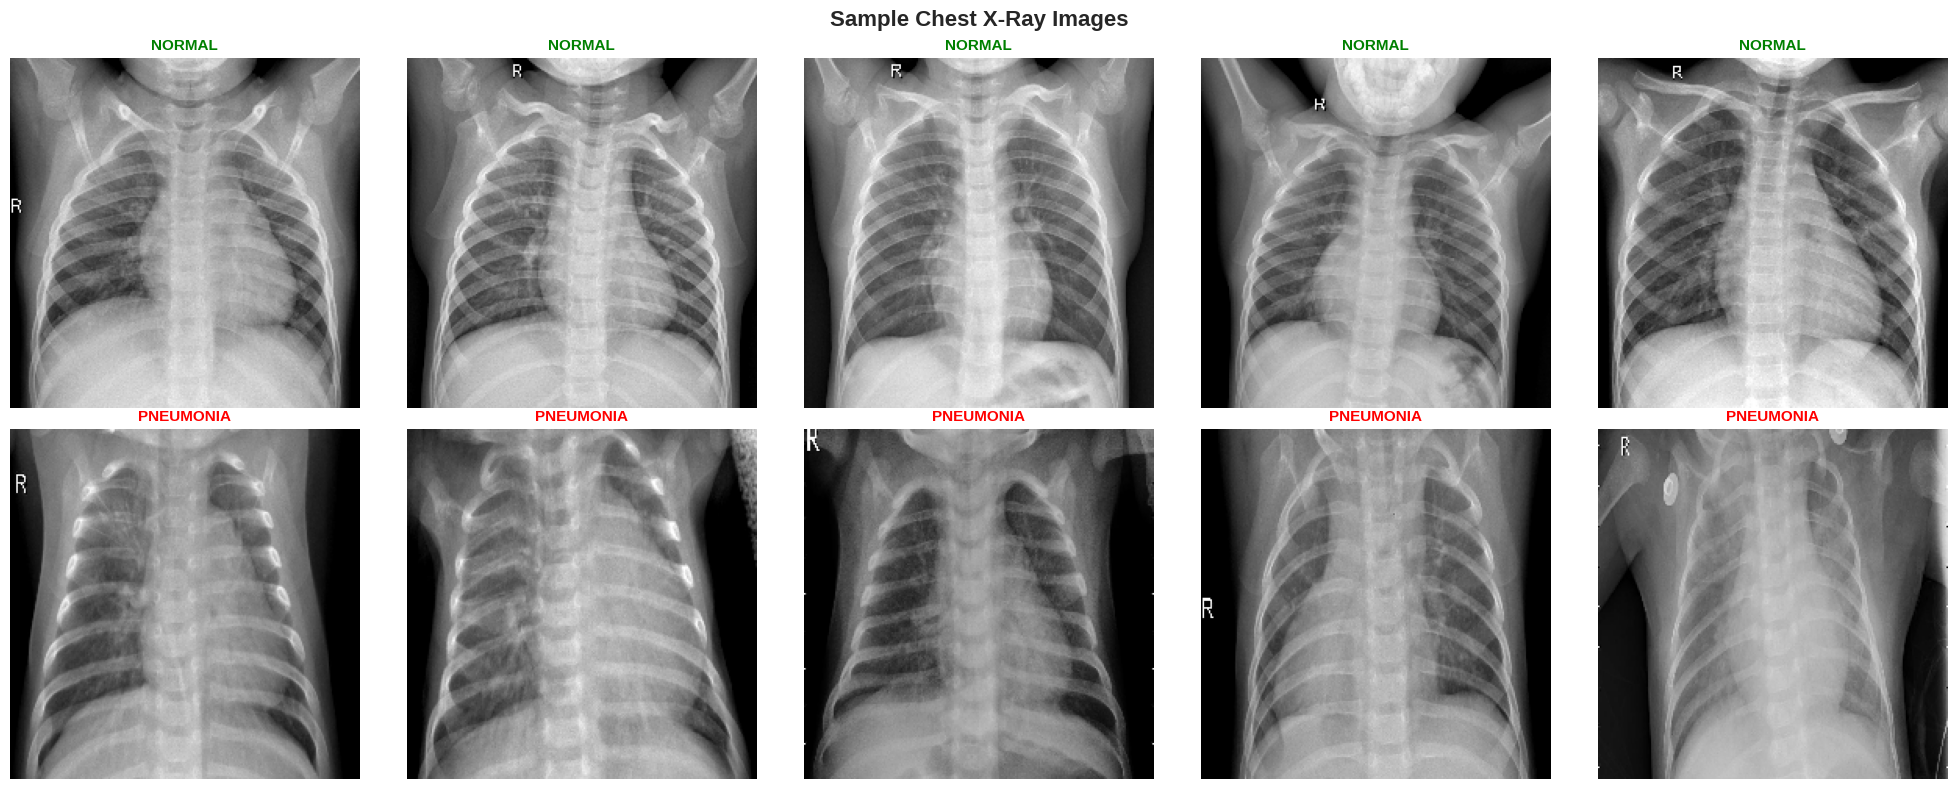

In [6]:
from tensorflow.keras.preprocessing.image import load_img

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

# Normal samples
normal_dir = os.path.join(TRAIN_DIR, 'NORMAL')
normal_imgs = random.sample(os.listdir(normal_dir), 5)
for i, img_name in enumerate(normal_imgs):
    img = load_img(os.path.join(normal_dir, img_name), target_size=(224, 224))
    axes[0, i].imshow(img, cmap='gray')
    axes[0, i].set_title('NORMAL', fontsize=11, color='green', fontweight='bold')
    axes[0, i].axis('off')

# Pneumonia samples
pneumonia_dir = os.path.join(TRAIN_DIR, 'PNEUMONIA')
pneumonia_imgs = random.sample(os.listdir(pneumonia_dir), 5)
for i, img_name in enumerate(pneumonia_imgs):
    img = load_img(os.path.join(pneumonia_dir, img_name), target_size=(224, 224))
    axes[1, i].imshow(img, cmap='gray')
    axes[1, i].set_title('PNEUMONIA', fontsize=11, color='red', fontweight='bold')
    axes[1, i].axis('off')

plt.suptitle('Sample Chest X-Ray Images', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_xrays.png', dpi=150, bbox_inches='tight')
plt.show()

# 6. PIXEL INTENSITY DISTRIBUTION ANALYSIS


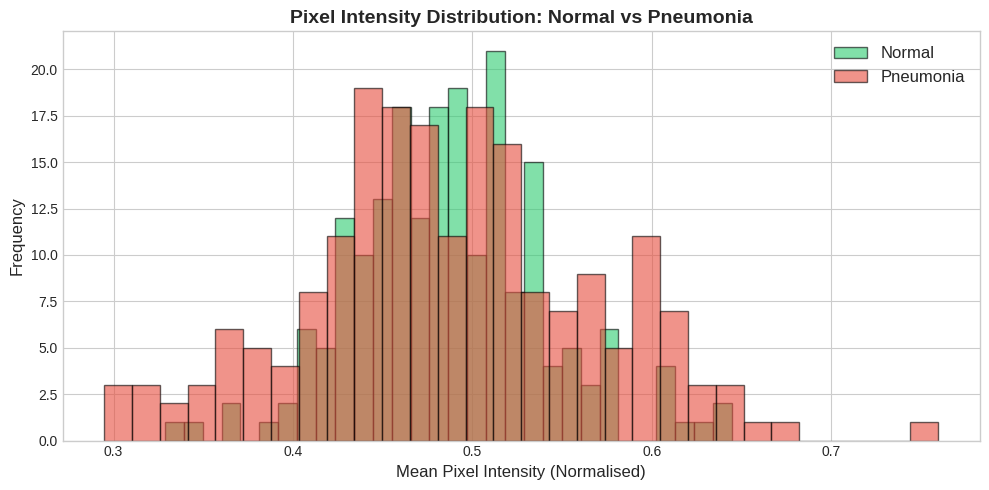

In [7]:
from tensorflow.keras.preprocessing.image import img_to_array

def get_pixel_intensities(directory, n_samples=200):
    """Collect mean pixel intensities from a sample of images."""
    files = random.sample(os.listdir(directory), min(n_samples, len(os.listdir(directory))))
    intensities = []
    for f in files:
        img = load_img(os.path.join(directory, f), target_size=(224, 224))
        arr = img_to_array(img) / 255.0
        intensities.append(arr.mean())
    return intensities

normal_intensities = get_pixel_intensities(os.path.join(TRAIN_DIR, 'NORMAL'))
pneumonia_intensities = get_pixel_intensities(os.path.join(TRAIN_DIR, 'PNEUMONIA'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(normal_intensities, bins=30, alpha=0.6, label='Normal', color='#2ecc71', edgecolor='black')
ax.hist(pneumonia_intensities, bins=30, alpha=0.6, label='Pneumonia', color='#e74c3c', edgecolor='black')
ax.set_xlabel('Mean Pixel Intensity (Normalised)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title('Pixel Intensity Distribution: Normal vs Pneumonia', fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig('pixel_intensity_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# 7. DATA PREPROCESSING & AUGMENTATION


In [8]:
IMG_SIZE = 128
BATCH_SIZE = 128

# Mixed precision for T4 GPU
tf.keras.mixed_precision.set_global_policy('mixed_float16')

# MINIMAL augmentation — less CPU overhead
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    seed=SEED,
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    seed=SEED,
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    seed=SEED,
    shuffle=False
)

print(f"Class indices: {train_generator.class_indices}")
print(f"Training samples:   {train_generator.samples}")
print(f"Steps per epoch:    {len(train_generator)}")

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Training samples:   5216
Steps per epoch:    41


# 8. VISUALISE AUGMENTED TRAINING IMAGES


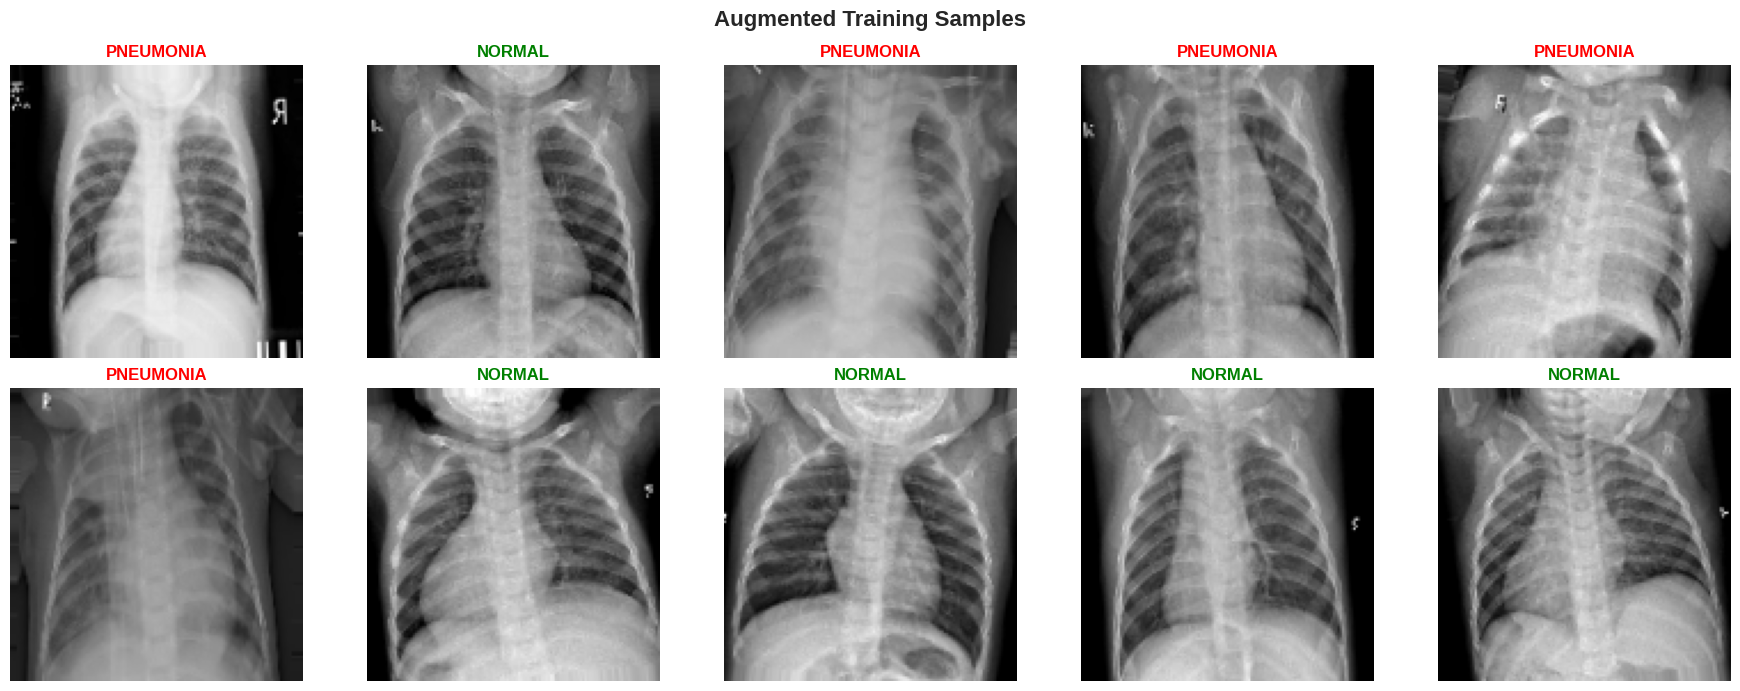

In [9]:
sample_batch, sample_labels = next(train_generator)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
label_map = {0: 'NORMAL', 1: 'PNEUMONIA'}
colour_map = {0: 'green', 1: 'red'}

for i, ax in enumerate(axes.flatten()):
    ax.imshow(sample_batch[i])
    lbl = int(sample_labels[i])
    ax.set_title(label_map[lbl], color=colour_map[lbl], fontweight='bold')
    ax.axis('off')

plt.suptitle('Augmented Training Samples', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('augmented_samples.png', dpi=150, bbox_inches='tight')
plt.show()

# 9. COMPUTE CLASS WEIGHTS FOR IMBALANCED DATA


In [10]:
from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_generator.classes
)
class_weights = {0: class_weights_array[0], 1: class_weights_array[1]}

print(f"Class weights: {class_weights}")
print(f"  NORMAL (0):    {class_weights[0]:.4f}")
print(f"  PNEUMONIA (1): {class_weights[1]:.4f}")

Class weights: {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}
  NORMAL (0):    1.9448
  PNEUMONIA (1): 0.6730


# 10. MODEL 1 — MobileNetV2


In [11]:
from tensorflow.keras.applications import MobileNetV2

def build_mobilenet_model(input_shape=(128, 128, 3)):
    base_model = MobileNetV2(weights='imagenet', include_top=False,
                              input_shape=input_shape, alpha=0.75)  # alpha=0.75 = 75% width, faster

    for layer in base_model.layers:
        layer.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    output = Dense(1, activation='sigmoid', dtype='float32')(x)

    model = Model(inputs=base_model.input, outputs=output)
    model.compile(optimizer=Adam(learning_rate=1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

mobilenet_model = build_mobilenet_model()
print(f"MobileNetV2 — Total params: {mobilenet_model.count_params():,}")

5903360/5903360 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 — Total params: 1,546,161


# 11. MODEL 2 — RESNET50 TRANSFER LEARNING

In [12]:
def build_resnet50_model(input_shape=(128, 128, 3)):
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)

    for layer in base_model.layers:
        layer.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    output = Dense(1, activation='sigmoid', dtype='float32')(x)

    model = Model(inputs=base_model.input, outputs=output)
    model.compile(optimizer=Adam(learning_rate=1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

resnet50_model = build_resnet50_model()
print(f"ResNet50 — Total params: {resnet50_model.count_params():,}")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
ResNet50 — Total params: 23,850,113


# 12. DEFINE TRAINING CALLBACKS


In [14]:
def get_callbacks(model_name):
    return [
        EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-7, verbose=1),
        ModelCheckpoint(f'best_{model_name}.keras', monitor='val_loss',
                        save_best_only=True, verbose=0)
    ]

EPOCHS = 8
STEPS_PER_EPOCH = 30

# 13. TRAIN ALL THREE MODELS


In [15]:
import time

print("=" * 60)
print("TRAINING MODEL 1: MobileNetV2")
print("=" * 60)
t0 = time.time()
history_mobilenet = mobilenet_model.fit(
    train_generator, epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_generator, class_weight=class_weights,
    callbacks=get_callbacks('mobilenet'), verbose=1
)
print(f"MobileNetV2 trained in {(time.time()-t0)/60:.1f} min\n")

print("=" * 60)
print("TRAINING MODEL 2: ResNet50")
print("=" * 60)
t0 = time.time()
history_resnet50 = resnet50_model.fit(
    train_generator, epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_generator, class_weight=class_weights,
    callbacks=get_callbacks('resnet50'), verbose=1
)
print(f"ResNet50 trained in {(time.time()-t0)/60:.1f} min\n")

TRAINING MODEL 1: MobileNetV2
Epoch 1/8
30/30 ━━━━━━━━━━━━━━━━━━━━ 122s 3s/step - accuracy: 0.8682 - loss: 0.2801 - val_accuracy: 0.9375 - val_loss: 0.3090 - learning_rate: 0.0010
Epoch 2/8
30/30 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.9164 - loss: 0.1910 - val_accuracy: 0.8750 - val_loss: 0.2490 - learning_rate: 0.0010
Epoch 3/8
30/30 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.9412 - loss: 0.1532 - val_accuracy: 0.9375 - val_loss: 0.1826 - learning_rate: 0.0010
Epoch 4/8
11/30 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.9407 - loss: 0.1459
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 530ms/step - accuracy: 0.9453 - loss: 0.1361 - val_accuracy: 0.9375 - val_loss: 0.1868 - learning_rate: 0.0010
Epoch 5/8
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9380 - loss: 0.1459
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
30/30 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.9424 - los

# 14. TRAINING HISTORY — ACCURACY & LOSS CURVES


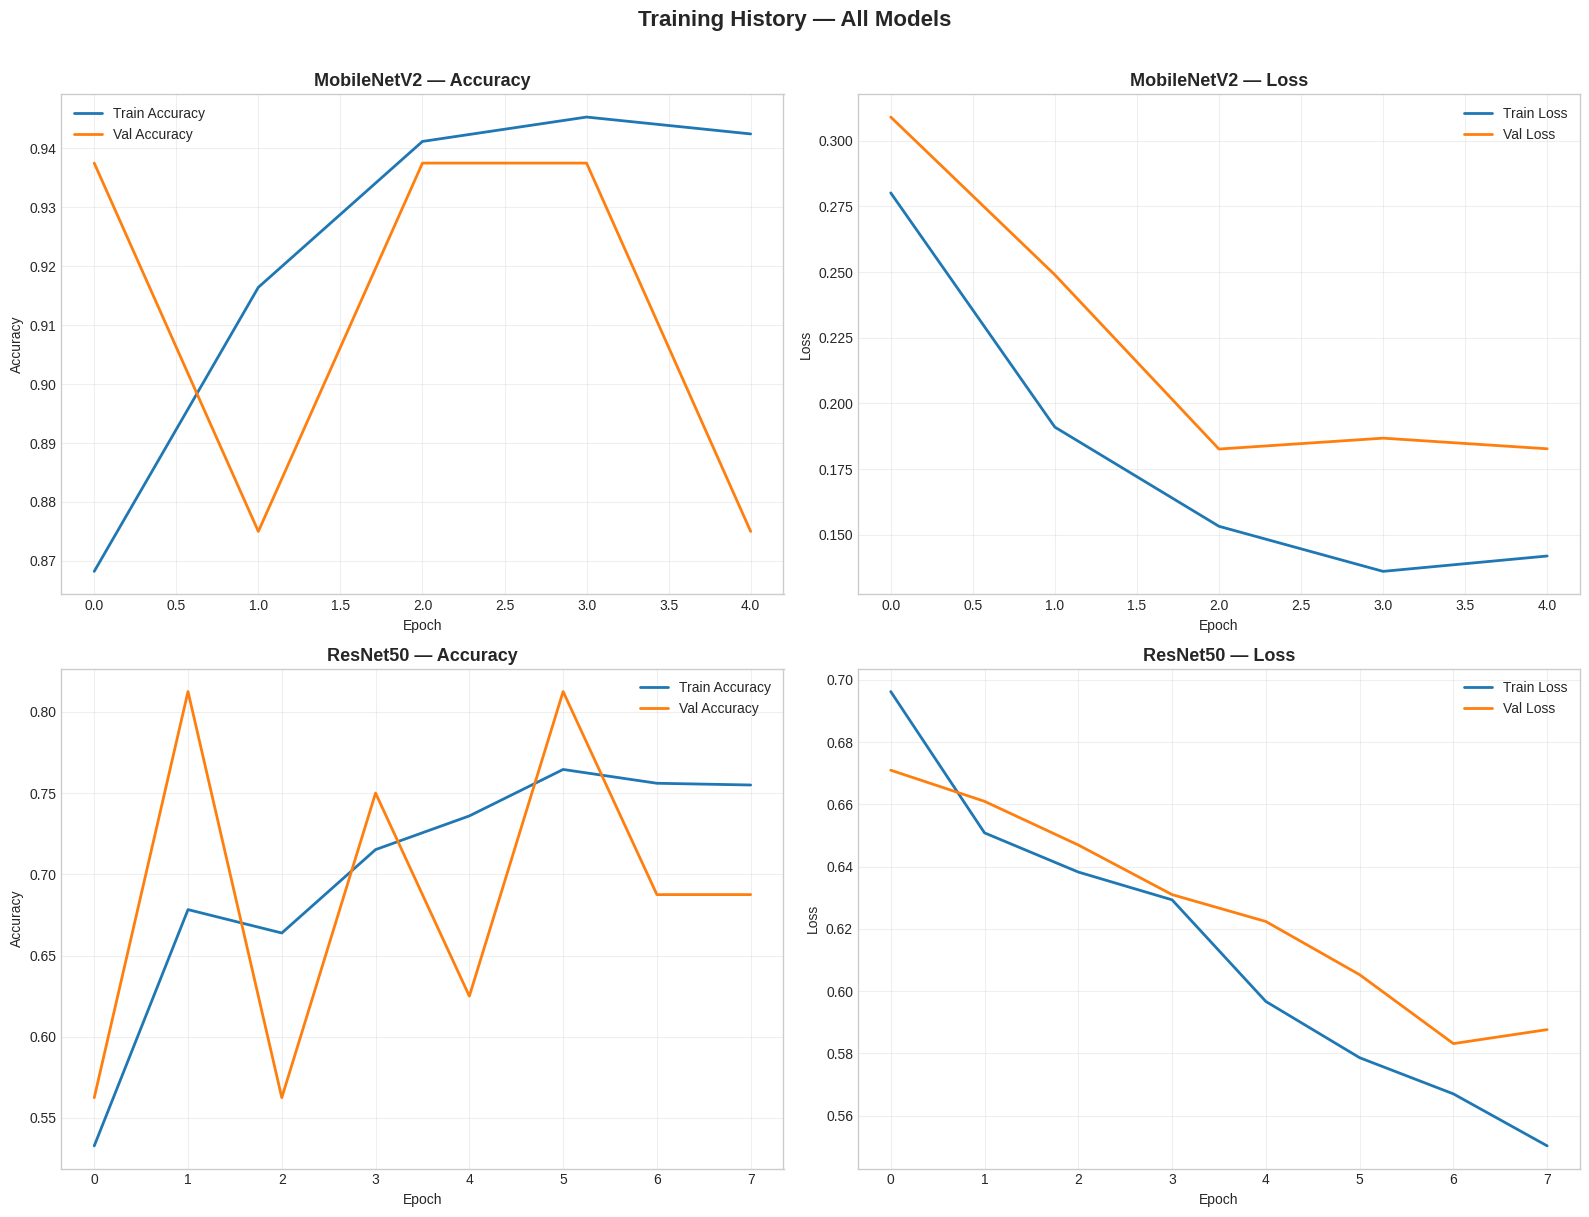

In [17]:
histories = {
    'MobileNetV2': history_mobilenet,
    'ResNet50': history_resnet50
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for idx, (name, history) in enumerate(histories.items()):
    axes[idx, 0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    axes[idx, 0].plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
    axes[idx, 0].set_title(f'{name} — Accuracy', fontsize=13, fontweight='bold')
    axes[idx, 0].set_xlabel('Epoch')
    axes[idx, 0].set_ylabel('Accuracy')
    axes[idx, 0].legend()
    axes[idx, 0].grid(True, alpha=0.3)

    axes[idx, 1].plot(history.history['loss'], label='Train Loss', linewidth=2)
    axes[idx, 1].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    axes[idx, 1].set_title(f'{name} — Loss', fontsize=13, fontweight='bold')
    axes[idx, 1].set_xlabel('Epoch')
    axes[idx, 1].set_ylabel('Loss')
    axes[idx, 1].legend()
    axes[idx, 1].grid(True, alpha=0.3)

plt.suptitle('Training History — All Models', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

# 15. MODEL EVALUATION ON TEST SET


In [18]:
models = {
    'MobileNetV2': mobilenet_model,
    'ResNet50': resnet50_model
}

results = {}
predictions = {}

for name, model in models.items():
    print(f"\n{'=' * 50}")
    print(f"EVALUATING: {name}")
    print('=' * 50)

    test_generator.reset()
    y_pred_prob = model.predict(test_generator, verbose=1).flatten()
    y_pred = (y_pred_prob >= 0.5).astype(int)
    y_true = test_generator.classes

    predictions[name] = {'y_true': y_true, 'y_pred': y_pred, 'y_prob': y_pred_prob}

    report = classification_report(y_true, y_pred,
                                    target_names=['NORMAL', 'PNEUMONIA'],
                                    output_dict=True)
    print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))

    test_generator.reset()
    test_loss, test_acc = model.evaluate(test_generator, verbose=0)

    results[name] = {
        'Test Accuracy': test_acc,
        'Test Loss': test_loss,
        'Precision': report['weighted avg']['precision'],
        'Recall': report['weighted avg']['recall'],
        'F1-Score': report['weighted avg']['f1-score']
    }

results_df = pd.DataFrame(results).T
print("\n" + "=" * 60)
print("COMPARATIVE RESULTS SUMMARY")
print("=" * 60)
print(results_df.round(4).to_string())


EVALUATING: MobileNetV2
5/5 ━━━━━━━━━━━━━━━━━━━━ 45s 7s/step
              precision    recall  f1-score   support

      NORMAL       0.84      0.85      0.85       234
   PNEUMONIA       0.91      0.90      0.91       390

    accuracy                           0.88       624
   macro avg       0.87      0.88      0.88       624
weighted avg       0.88      0.88      0.88       624


EVALUATING: ResNet50
5/5 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step
              precision    recall  f1-score   support

      NORMAL       0.65      0.84      0.73       234
   PNEUMONIA       0.88      0.73      0.80       390

    accuracy                           0.77       624
   macro avg       0.77      0.78      0.76       624
weighted avg       0.80      0.77      0.77       624


COMPARATIVE RESULTS SUMMARY
             Test Accuracy  Test Loss  Precision  Recall  F1-Score
MobileNetV2         0.8830     0.3063     0.8833  0.8830    0.8832
ResNet50            0.7692     0.5597     0.7957  0.7692    0.

# 16. CONFUSION MATRICES

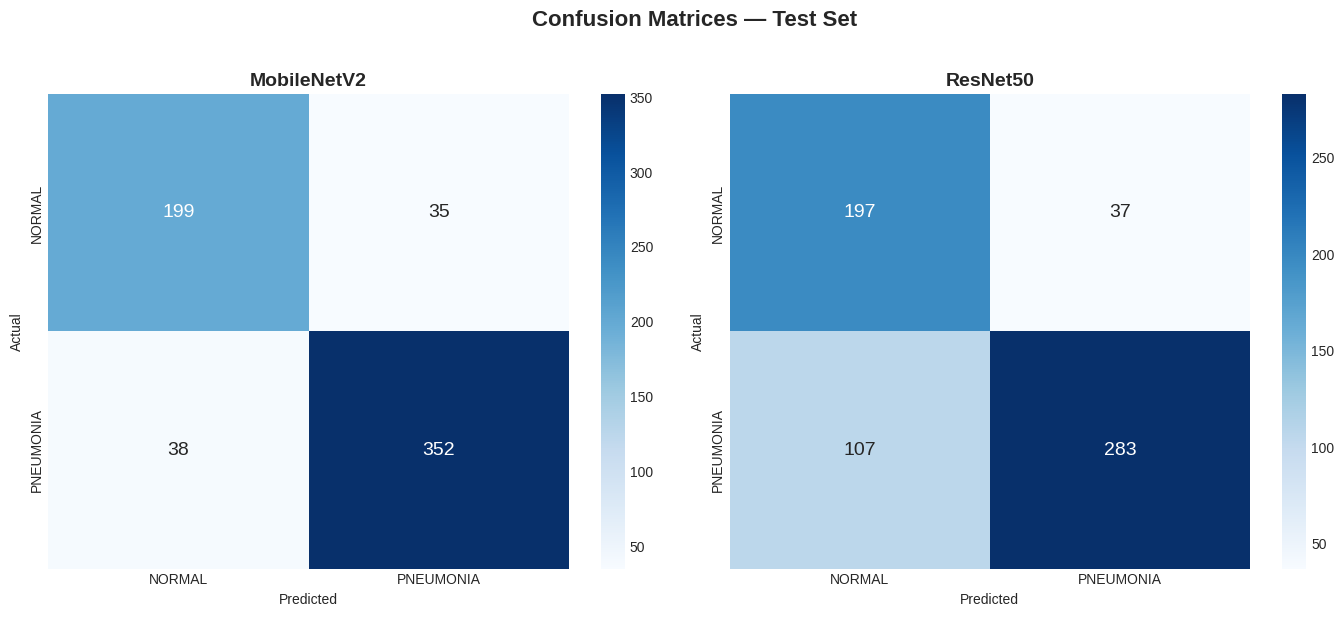

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for idx, (name, preds) in enumerate(predictions.items()):
    cm = confusion_matrix(preds['y_true'], preds['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['NORMAL', 'PNEUMONIA'],
                yticklabels=['NORMAL', 'PNEUMONIA'],
                annot_kws={'size': 14})
    axes[idx].set_title(f'{name}', fontsize=14, fontweight='bold')
    axes[idx].set_ylabel('Actual')
    axes[idx].set_xlabel('Predicted')

plt.suptitle('Confusion Matrices — Test Set', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

# 17. ROC CURVES

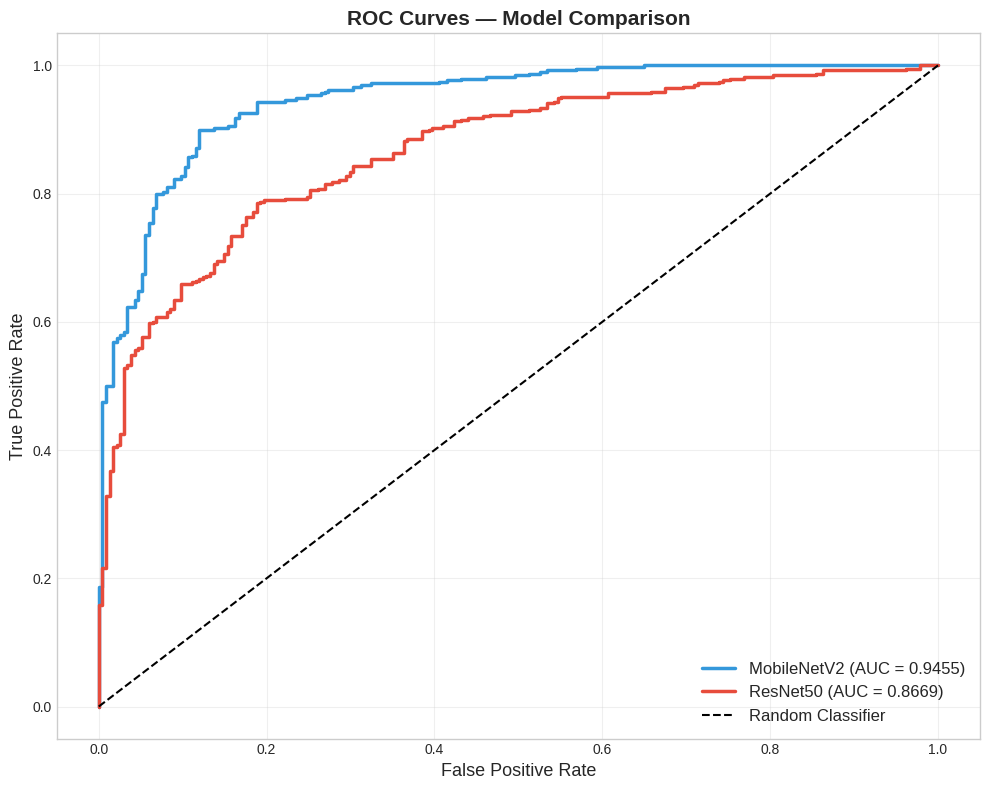

In [20]:
fig, ax = plt.subplots(figsize=(10, 8))
colors_roc = ['#3498db', '#e74c3c']

for idx, (name, preds) in enumerate(predictions.items()):
    fpr, tpr, _ = roc_curve(preds['y_true'], preds['y_prob'])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors_roc[idx], linewidth=2.5,
            label=f'{name} (AUC = {roc_auc:.4f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('ROC Curves — Model Comparison', fontsize=15, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# 18. PRECISION-RECALL CURVES

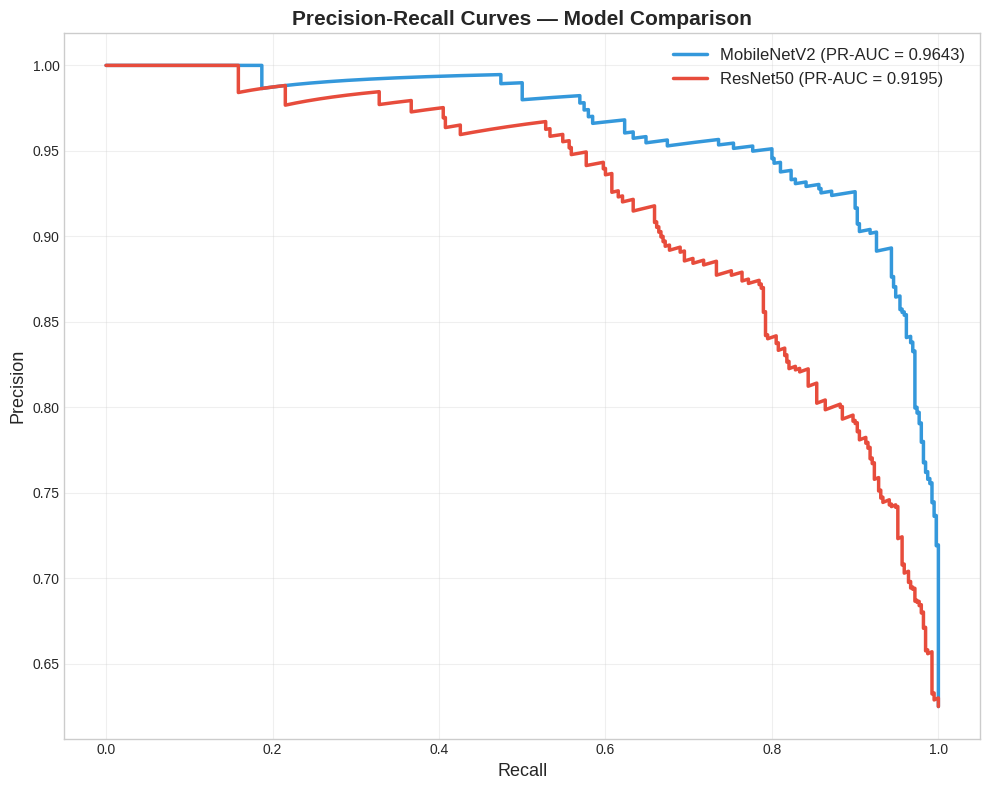

In [21]:
fig, ax = plt.subplots(figsize=(10, 8))

for idx, (name, preds) in enumerate(predictions.items()):
    precision_vals, recall_vals, _ = precision_recall_curve(preds['y_true'], preds['y_prob'])
    pr_auc = auc(recall_vals, precision_vals)
    ax.plot(recall_vals, precision_vals, color=colors_roc[idx], linewidth=2.5,
            label=f'{name} (PR-AUC = {pr_auc:.4f})')

ax.set_xlabel('Recall', fontsize=13)
ax.set_ylabel('Precision', fontsize=13)
ax.set_title('Precision-Recall Curves — Model Comparison', fontsize=15, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('precision_recall_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# 19. COMPARATIVE PERFORMANCE BAR CHART

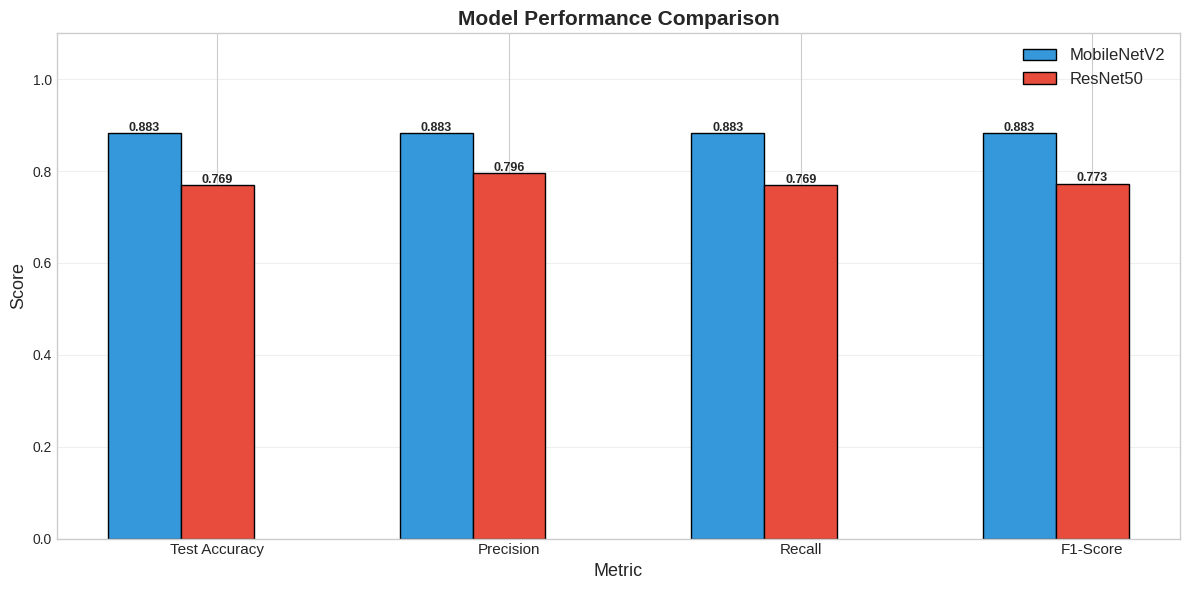

In [23]:
metrics_to_plot = ['Test Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics_to_plot))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for idx, (model_name, row) in enumerate(results_df.iterrows()):
    values = [row[m] for m in metrics_to_plot]
    bars = ax.bar(x + idx * width, values, width, label=model_name,
                  color=colors_roc[idx], edgecolor='black')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', fontsize=9, fontweight='bold')

ax.set_xlabel('Metric', fontsize=13)
ax.set_ylabel('Score', fontsize=13)
ax.set_title('Model Performance Comparison', fontsize=15, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(metrics_to_plot, fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=12)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('model_comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# 20. GRAD-CAM EXPLAINABILITY


In [25]:
import cv2

def get_gradcam_heatmap(model, img_array, last_conv_layer_name):
    grad_model = Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, pred = grad_model(tf.cast(img_array, tf.float32))
        loss = pred[:, 0]
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy().astype(np.float32)   # <-- FIX: cast to float32


def display_gradcam(model, img_path, last_conv_layer_name, img_size=128):
    img = load_img(img_path, target_size=(img_size, img_size))
    img_array = img_to_array(img).astype(np.float32) / 255.0
    img_array_batch = np.expand_dims(img_array, axis=0)

    heatmap = get_gradcam_heatmap(model, img_array_batch, last_conv_layer_name)
    heatmap_resized = cv2.resize(heatmap, (img_size, img_size))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    superimposed = (heatmap_color / 255.0) * 0.4 + img_array
    superimposed = np.clip(superimposed, 0, 1)

    pred = float(model.predict(img_array_batch, verbose=0)[0][0])
    pred_label = 'PNEUMONIA' if pred >= 0.5 else 'NORMAL'
    return img_array, superimposed, pred_label, pred


last_conv_layers = {
    'MobileNetV2': 'Conv_1',
    'ResNet50': 'conv5_block3_out'
}

print("Last conv layers for Grad-CAM:")
for k, v in last_conv_layers.items():
    print(f"  {k}: {v}")

Last conv layers for Grad-CAM:
  MobileNetV2: Conv_1
  ResNet50: conv5_block3_out


# 21. GRAD-CAM GRID — NORMAL & PNEUMONIA SAMPLES


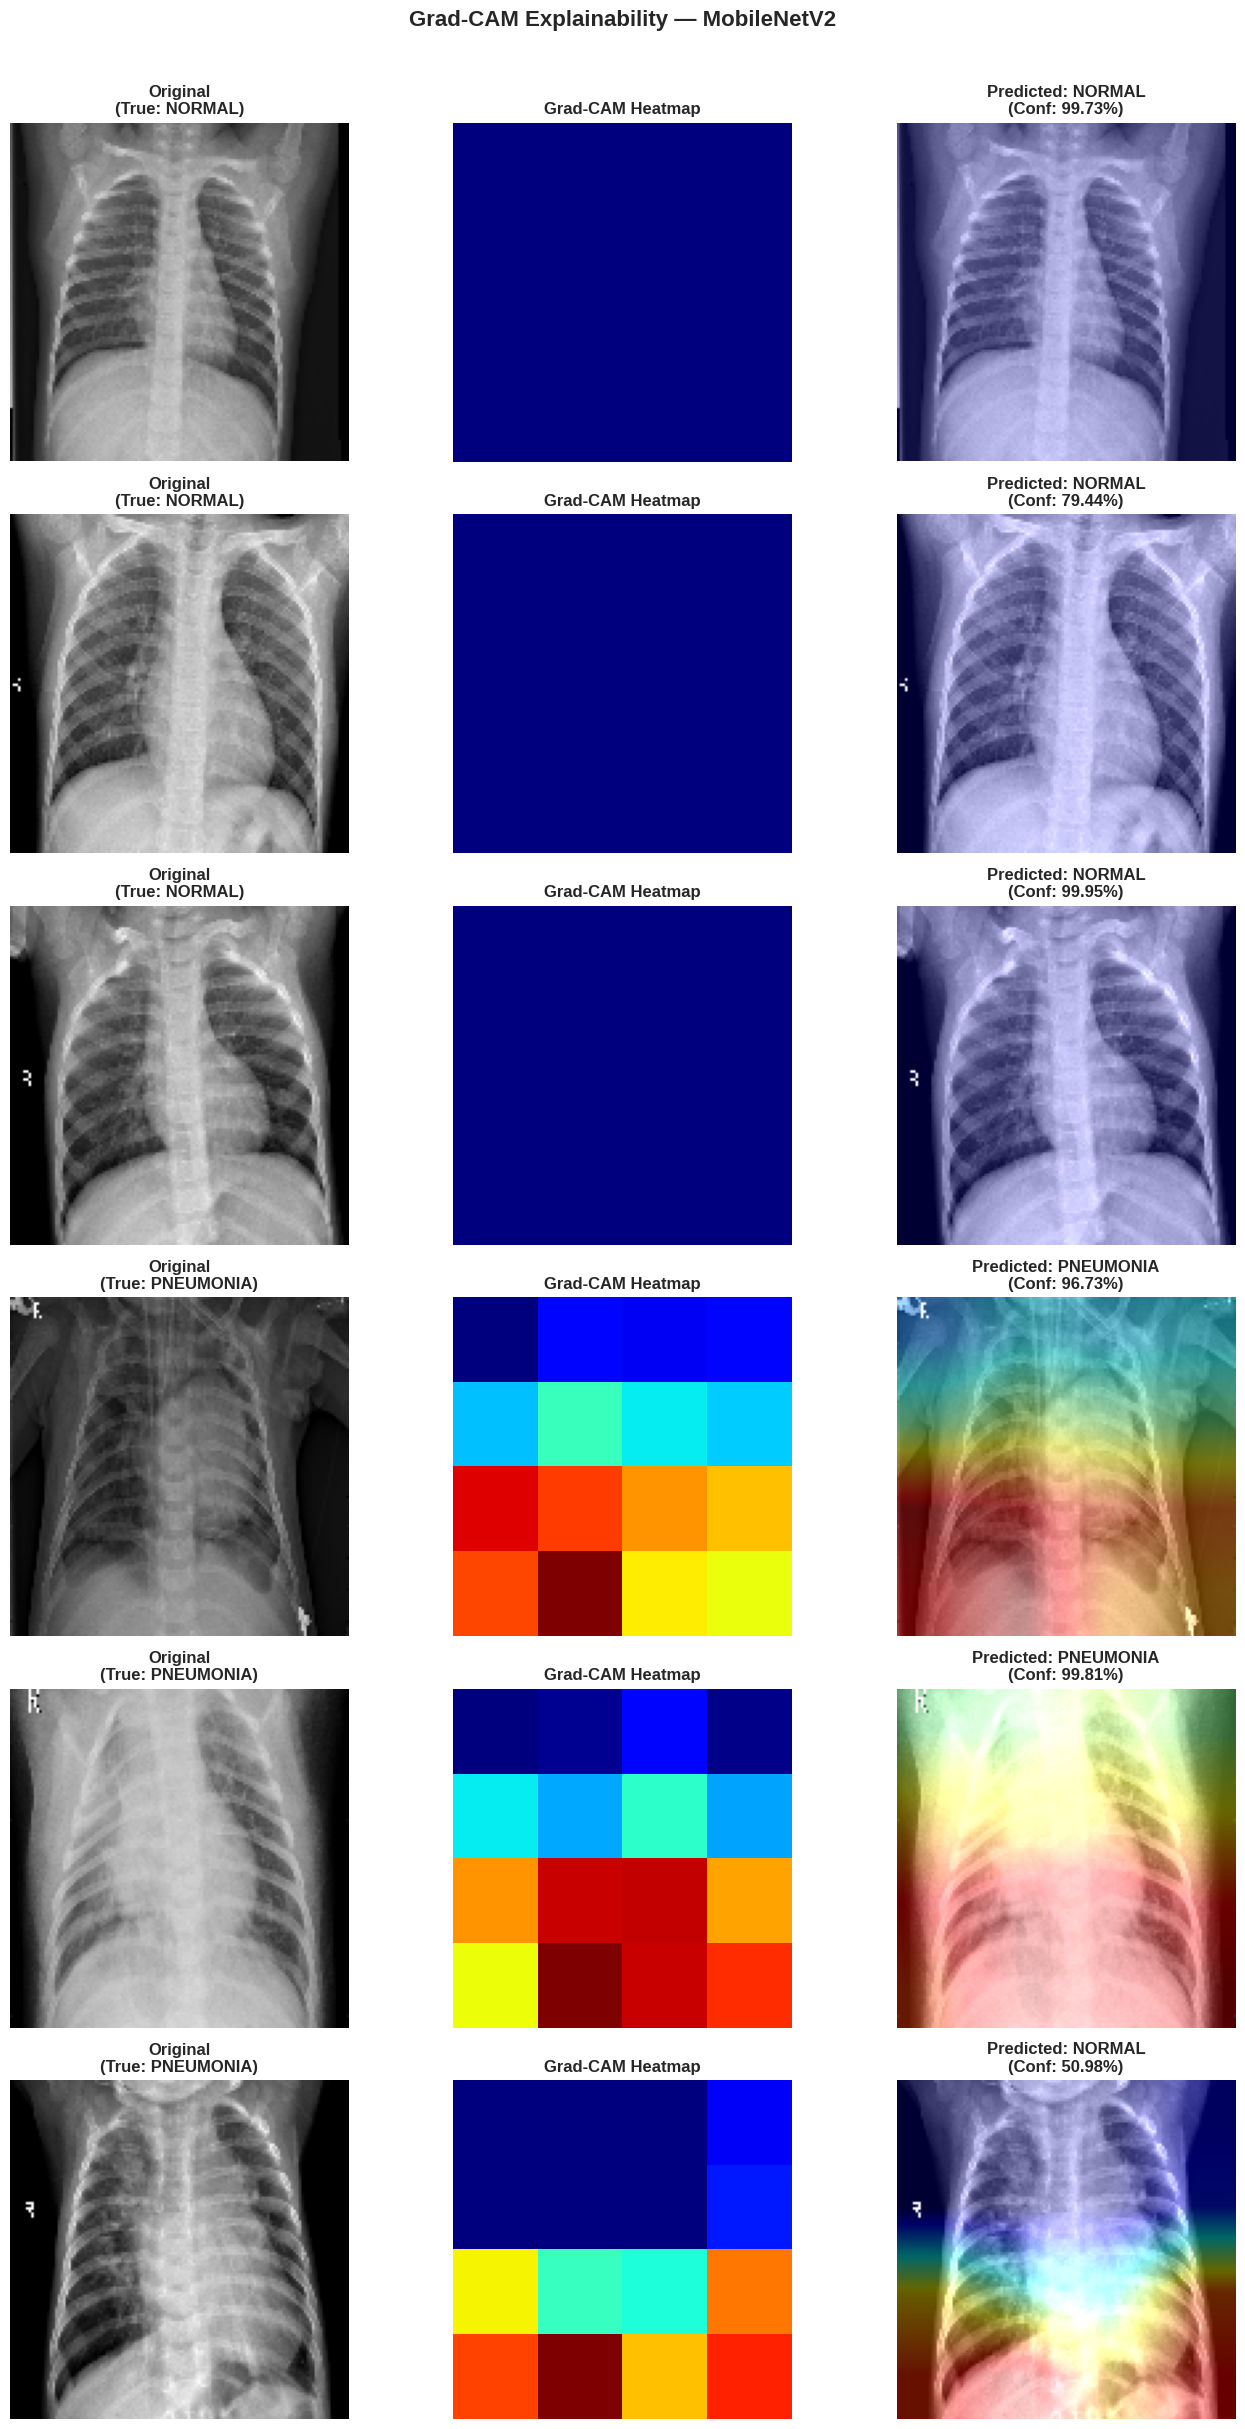

In [26]:
test_normal_dir = os.path.join(TEST_DIR, 'NORMAL')
test_pneumonia_dir = os.path.join(TEST_DIR, 'PNEUMONIA')

sample_normal = [os.path.join(test_normal_dir, f) for f in random.sample(os.listdir(test_normal_dir), 3)]
sample_pneumonia = [os.path.join(test_pneumonia_dir, f) for f in random.sample(os.listdir(test_pneumonia_dir), 3)]
sample_images = sample_normal + sample_pneumonia
sample_true_labels = ['NORMAL'] * 3 + ['PNEUMONIA'] * 3

best_model_name = results_df['F1-Score'].idxmax()
best_model = models[best_model_name]
best_conv_layer = last_conv_layers[best_model_name]

fig, axes = plt.subplots(len(sample_images), 3, figsize=(14, len(sample_images) * 4))

for i, img_path in enumerate(sample_images):
    original, gradcam_overlay, pred_label, pred_conf = display_gradcam(
        best_model, img_path, best_conv_layer, img_size=IMG_SIZE
    )

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f'Original\n(True: {sample_true_labels[i]})', fontweight='bold')
    axes[i, 0].axis('off')

    img_arr = img_to_array(load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))) / 255.0
    heatmap = get_gradcam_heatmap(best_model, np.expand_dims(img_arr, 0), best_conv_layer)
    axes[i, 1].imshow(heatmap, cmap='jet')
    axes[i, 1].set_title('Grad-CAM Heatmap', fontweight='bold')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(gradcam_overlay)
    conf = pred_conf if pred_label == 'PNEUMONIA' else 1 - pred_conf
    axes[i, 2].set_title(f'Predicted: {pred_label}\n(Conf: {conf:.2%})', fontweight='bold')
    axes[i, 2].axis('off')

plt.suptitle(f'Grad-CAM Explainability — {best_model_name}', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('gradcam_results.png', dpi=150, bbox_inches='tight')
plt.show()

# 22. FINE-TUNING THE BEST MODEL


In [27]:
print(f"Fine-tuning: {best_model_name}\n")

if best_model_name == 'MobileNetV2':
    # Unfreeze last 20 layers of MobileNetV2
    for layer in best_model.layers[-20:]:
        layer.trainable = True
elif best_model_name == 'ResNet50':
    for layer in best_model.layers[-15:]:
        layer.trainable = True

best_model.compile(optimizer=Adam(learning_rate=1e-5),
                   loss='binary_crossentropy', metrics=['accuracy'])

t0 = time.time()
history_finetune = best_model.fit(
    train_generator, epochs=5, steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_generator, class_weight=class_weights,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-8, verbose=1)
    ],
    verbose=1
)
print(f"Fine-tuning done in {(time.time()-t0)/60:.1f} min")

test_generator.reset()
ft_loss, ft_acc = best_model.evaluate(test_generator, verbose=0)
test_generator.reset()
ft_preds = best_model.predict(test_generator, verbose=0).flatten()
ft_y_pred = (ft_preds >= 0.5).astype(int)

print(f"\n{'=' * 50}")
print(f"FINE-TUNED {best_model_name} — TEST RESULTS")
print('=' * 50)
print(f"Test Accuracy: {ft_acc:.4f}")
print(f"Test Loss:     {ft_loss:.4f}\n")
print(classification_report(test_generator.classes, ft_y_pred,
                              target_names=['NORMAL', 'PNEUMONIA']))

Fine-tuning: MobileNetV2

Epoch 1/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 119s 3s/step - accuracy: 0.9149 - loss: 0.2400 - val_accuracy: 0.9375 - val_loss: 0.1732 - learning_rate: 1.0000e-05
Epoch 2/5
11/30 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9144 - loss: 0.2124
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 385ms/step - accuracy: 0.9148 - loss: 0.2138 - val_accuracy: 0.9375 - val_loss: 0.1776 - learning_rate: 1.0000e-05
Epoch 3/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9282 - loss: 0.1851
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
30/30 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.9228 - loss: 0.1982 - val_accuracy: 0.9375 - val_loss: 0.1833 - learning_rate: 5.0000e-06
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
Fine-tuning done in 3.0 min

FINE-TUNED MobileNetV2 — TEST RESULTS
Test Accuracy: 0.8878
Test Loss:     0.3189

              preci

# 23. FINAL RESULTS SUMMARY TABLE

In [28]:
ft_report = classification_report(test_generator.classes, ft_y_pred,
                                    target_names=['NORMAL', 'PNEUMONIA'],
                                    output_dict=True)
results[f'{best_model_name} (Fine-Tuned)'] = {
    'Test Accuracy': ft_acc,
    'Test Loss': ft_loss,
    'Precision': ft_report['weighted avg']['precision'],
    'Recall': ft_report['weighted avg']['recall'],
    'F1-Score': ft_report['weighted avg']['f1-score']
}

final_results_df = pd.DataFrame(results).T
final_results_df = final_results_df.sort_values('F1-Score', ascending=False)

print("=" * 70)
print("FINAL MODEL COMPARISON — ALL MODELS INCLUDING FINE-TUNED")
print("=" * 70)
print(final_results_df.round(4).to_string())
print("\n")

best_final = final_results_df['F1-Score'].idxmax()
print(f"BEST OVERALL MODEL: {best_final}")
print(f"  Accuracy:  {final_results_df.loc[best_final, 'Test Accuracy']:.4f}")
print(f"  Precision: {final_results_df.loc[best_final, 'Precision']:.4f}")
print(f"  Recall:    {final_results_df.loc[best_final, 'Recall']:.4f}")
print(f"  F1-Score:  {final_results_df.loc[best_final, 'F1-Score']:.4f}")

FINAL MODEL COMPARISON — ALL MODELS INCLUDING FINE-TUNED
                          Test Accuracy  Test Loss  Precision  Recall  F1-Score
MobileNetV2 (Fine-Tuned)         0.8878     0.3189     0.8873  0.8878    0.8874
MobileNetV2                      0.8830     0.3063     0.8833  0.8830    0.8832
ResNet50                         0.7692     0.5597     0.7957  0.7692    0.7729


BEST OVERALL MODEL: MobileNetV2 (Fine-Tuned)
  Accuracy:  0.8878
  Precision: 0.8873
  Recall:    0.8878
  F1-Score:  0.8874


# 24. SAVE FINAL MODEL & EXPORT RESULTS

In [29]:
# Save final model
best_model.save('pneumonia_detector_final.keras')
print("Final model saved: pneumonia_detector_final.keras")

# Save results to CSV
final_results_df.to_csv('model_comparison_results.csv')
print("Results saved: model_comparison_results.csv")

# Save training histories
import json

all_histories = {}
for name, hist in histories.items():
    all_histories[name] = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
all_histories[f'{best_model_name}_finetuned'] = {
    k: [float(v) for v in vals] for k, vals in history_finetune.history.items()
}

with open('training_histories.json', 'w') as f:
    json.dump(all_histories, f, indent=2)
print("Training histories saved: training_histories.json")

# Download all artefacts
from google.colab import files
for fname in ['pneumonia_detector_final.keras', 'model_comparison_results.csv',
              'training_histories.json', 'class_distribution.png', 'sample_xrays.png',
              'pixel_intensity_distribution.png', 'augmented_samples.png',
              'training_history.png', 'confusion_matrices.png', 'roc_curves.png',
              'precision_recall_curves.png', 'model_comparison_bar.png',
              'gradcam_results.png']:
    if os.path.exists(fname):
        files.download(fname)

print("\nAll artefacts downloaded successfully!")

Final model saved: pneumonia_detector_final.keras
Results saved: model_comparison_results.csv
Training histories saved: training_histories.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All artefacts downloaded successfully!
